In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Cats/cat..jfif
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Cats/cat.jfif
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Dogs/dog..jfif
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Dogs/dog.jfif
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Elephants/elephant..jfif
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Elephants/elephant.jfif
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Lion/black-maned-lion-shem-compion-786x500.jpg
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Lion/lion-animal-isolated-photo.jpg
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Tigers/images (6).jfif
/kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai/Tigers/images (7).jfif


In [7]:
import os

dataset_path = (
    "/kaggle/input/datasets/sharriniazi/"
    "animal-detection-ai/Animal Detection Ai"
)

print("Dataset path:", dataset_path)

if not os.path.isdir(dataset_path):
    raise FileNotFoundError(
        f"Dataset folder not found: {dataset_path}"
    )

print("\nFolders found:", os.listdir(dataset_path))

Dataset path: /kaggle/input/datasets/sharriniazi/animal-detection-ai/Animal Detection Ai

Folders found: ['Cats', 'Dogs', 'Elephants', 'Lion', 'Tigers']


In [9]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [12]:
import os
from PIL import Image

SOURCE_DIR = dataset_path
FIXED_DIR = "/kaggle/working/animal_images_jpg"

os.makedirs(FIXED_DIR, exist_ok=True)

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif", ".jfif")

converted = 0
failed = []

for animal in os.listdir(SOURCE_DIR):
    source_class = os.path.join(SOURCE_DIR, animal)

    if not os.path.isdir(source_class):
        continue

    target_class = os.path.join(FIXED_DIR, animal)
    os.makedirs(target_class, exist_ok=True)

    for filename in os.listdir(source_class):
        if not filename.lower().endswith(valid_extensions):
            continue

        source_file = os.path.join(source_class, filename)
        target_file = os.path.join(
            target_class,
            os.path.splitext(filename)[0] + ".jpg"
        )

        try:
            with Image.open(source_file) as img:
                img.convert("RGB").save(target_file, "JPEG", quality=95)
                converted += 1
        except Exception as e:
            failed.append((source_file, str(e)))

print("Images converted:", converted)
print("Images that failed:", len(failed))
print("New dataset location:", FIXED_DIR)

for item in failed[:5]:
    print(item)

Images converted: 10
Images that failed: 0
New dataset location: /kaggle/working/animal_images_jpg


In [13]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    FIXED_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    FIXED_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Animal classes:", class_names)
print("Number of classes:", len(class_names))

assert len(class_names) == 5, "Expected five animal classes."

Found 10 files belonging to 5 classes.
Using 8 files for training.
Found 10 files belonging to 5 classes.
Using 2 files for validation.
Animal classes: ['Cats', 'Dogs', 'Elephants', 'Lion', 'Tigers']
Number of classes: 5


2026-10-23 06:43:02.759924: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


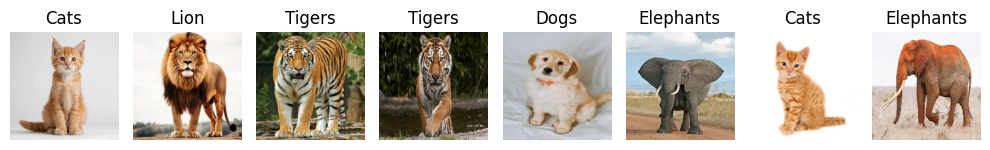

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(len(images)):
        plt.subplot(4, 8, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Training and validation datasets are ready.")
print("Classes:", class_names)

Training and validation datasets are ready.
Classes: ['Cats', 'Dogs', 'Elephants', 'Lion', 'Tigers']


In [18]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    # Normalize pixel values
    layers.Rescaling(1.0 / 255),

    # Learn image features
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # Five animal classes
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3750 - loss: 1.5975 - val_accuracy: 0.0000e+00 - val_loss: 7.8425
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.2500 - loss: 3.2045 - val_accuracy: 0.0000e+00 - val_loss: 3.5212
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step - accuracy: 0.3750 - loss: 2.5830 - val_accuracy: 0.5000 - val_loss: 1.5985
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step - accuracy: 0.3750 - loss: 1.7926 - val_accuracy: 0.5000 - val_loss: 1.4944
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step - accuracy: 0.3750 - loss: 1.4405 - val_accuracy: 0.0000e+00 - val_loss: 1.7387
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 613ms/step - accuracy: 0.5000 - loss: 1.2416 - val_accuracy: 0.0000e+00 - val_loss: 1.7004
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 351ms/step - accuracy: 0.7500 - loss: 1.2213 - val_accuracy: 0.0000e+00 - val_loss: 1.7746
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step - accuracy: 0.8750 - loss: 1.0152 - val_accuracy: 0

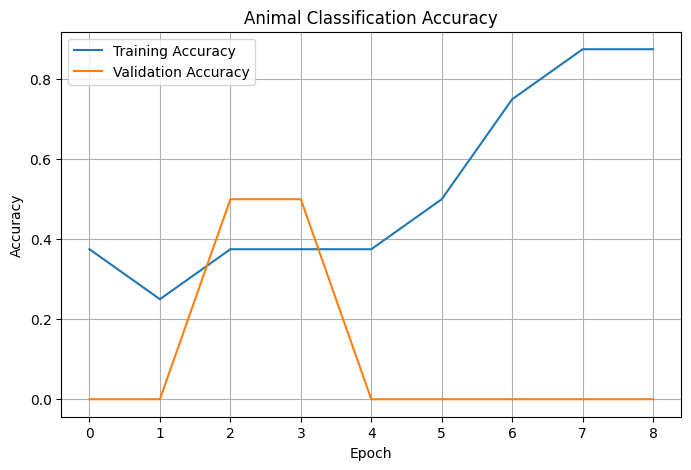

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Animal Classification Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
val_loss, val_accuracy = model.evaluate(val_ds)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5000 - loss: 1.4944
Validation Loss: 1.4944
Validation Accuracy: 50.00%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step


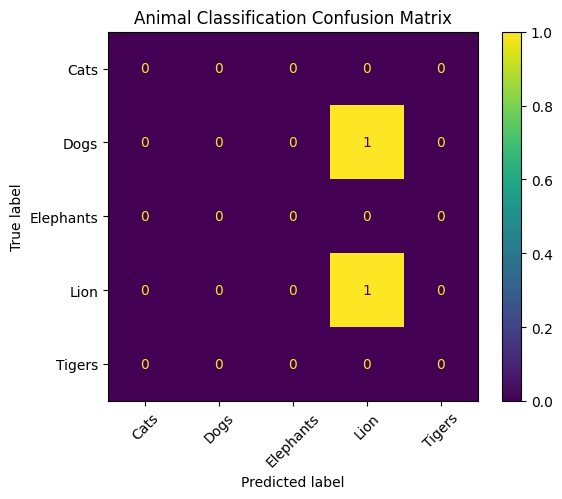

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_probs = model.predict(val_ds)
y_pred = np.argmax(y_probs, axis=1)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(xticks_rotation=45)
plt.title("Animal Classification Confusion Matrix")
plt.show()

In [23]:
import json
import os

model_path = "/kaggle/working/animal_classifier.keras"
labels_path = "/kaggle/working/class_names.json"

model.save(model_path)

with open(labels_path, "w") as f:
    json.dump(class_names, f)

print("Model saved:", model_path)
print("Labels saved:", labels_path)

Model saved: /kaggle/working/animal_classifier.keras
Labels saved: /kaggle/working/class_names.json


In [24]:
import io
import numpy as np
import ipywidgets as widgets

from PIL import Image
from IPython.display import display, clear_output

image_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Choose Image"
)

predict_button = widgets.Button(
    description="Detect Animal",
    button_style="success"
)

output = widgets.Output()

def predict_animal(button):
    with output:
        clear_output()

        uploaded = image_upload.value

        if not uploaded:
            print("Please choose an image first.")
            return

        # Support both ipywidgets data formats
        if isinstance(uploaded, dict):
            file_info = next(iter(uploaded.values()))
        else:
            file_info = uploaded[0]

        image_bytes = file_info["content"]

        try:
            img = Image.open(
                io.BytesIO(bytes(image_bytes))
            ).convert("RGB")

            display(img)

            img = img.resize((180, 180))

            img_array = np.array(
                img, dtype=np.float32
            )
            img_array = np.expand_dims(
                img_array, axis=0
            )

            predictions = model.predict(
                img_array, verbose=0
            )[0]

            best_index = int(np.argmax(predictions))
            predicted_animal = class_names[best_index]
            confidence = predictions[best_index] * 100

            print("Predicted Animal:", predicted_animal)
            print(f"Model Score: {confidence:.2f}%")

            print("\nScores for all classes:")
            for name, score in zip(class_names, predictions):
                print(f"{name}: {score * 100:.2f}%")

            if confidence < 50:
                print(
                    "\nLow confidence: try a clearer picture."
                )

        except Exception as error:
            print("Unable to process image:", error)

predict_button.on_click(predict_animal)

display(image_upload, predict_button, output)

FileUpload(value=(), accept='image/*', description='Choose Image')

Button(button_style='success', description='Detect Animal', style=ButtonStyle())

Output()

In [25]:
import json
import os

model_path = "/kaggle/working/animal_classifier.keras"
labels_path = "/kaggle/working/class_names.json"

model.save(model_path)

with open(labels_path, "w") as f:
    json.dump(class_names, f)

print("Model saved:", model_path)
print("Labels saved:", labels_path)

Model saved: /kaggle/working/animal_classifier.keras
Labels saved: /kaggle/working/class_names.json
